# Relação entre os resultados experimentais e a tolerância dos resistores

Este notebook compara, para cada resistor:

- o valor nominal $R_{\mathrm{nominal}}$;
- a faixa de tolerância de $\pm 5\%$ informada pelo fabricante;
- o resultado experimental $\bar R \pm s$, calculado a partir de três leituras.

A visualização principal usa a diferença percentual em relação ao valor nominal. Assim, resistores de valores muito diferentes podem ser comparados na mesma escala.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

## 1. Dados experimentais

As leituras são mantidas no notebook para que a média e o desvio-padrão possam ser recalculados, em vez de serem digitados como resultados prontos. O argumento `ddof=1` solicita o desvio-padrão **amostral**, cujo denominador é $n-1$.

In [2]:
resistores = ['R1', 'R2', 'R3', 'R4']
nominais = np.array([47.0, 100.0, 150.0, 330.0])
leituras = np.array([
    [48.6, 48.2, 48.1],
    [98.9, 98.8, 99.0],
    [151.0, 151.2, 151.7],
    [323.0, 327.0, 318.0],
])

medias = leituras.mean(axis=1)
desvios = leituras.std(axis=1, ddof=1)

medias, desvios

(array([ 48.3       ,  98.9       , 151.3       , 322.66666667]),
 array([0.26457513, 0.1       , 0.36055513, 4.50924975]))

## 2. Intervalos comparados

A faixa de tolerância do fabricante é calculada por

$$R_{\min}=0{,}95R_{\mathrm{nominal}}, \qquad R_{\max}=1{,}05R_{\mathrm{nominal}}.$$

O intervalo experimental utilizado no gráfico é $[\bar R-s,\bar R+s]$. Esse intervalo mostra a dispersão das três leituras; ele não deve ser interpretado automaticamente como um intervalo de confiança ou como uma avaliação completa da incerteza de medição.

In [3]:
tolerancia_inferior = nominais * 0.95
tolerancia_superior = nominais * 1.05
experimental_inferior = medias - desvios
experimental_superior = medias + desvios

diferenca_percentual = (medias - nominais) / nominais * 100
desvio_percentual = desvios / nominais * 100

contido_na_tolerancia = (
    (experimental_inferior >= tolerancia_inferior)
    & (experimental_superior <= tolerancia_superior)
)

resultado = pd.DataFrame({
    'Resistor': resistores,
    'Nominal (Ω)': nominais,
    'Média (Ω)': medias,
    's (Ω)': desvios,
    'Tol. inferior (Ω)': tolerancia_inferior,
    'Tol. superior (Ω)': tolerancia_superior,
    'Exp. inferior (Ω)': experimental_inferior,
    'Exp. superior (Ω)': experimental_superior,
    'Diferença (%)': diferenca_percentual,
    '±s relativo (%)': desvio_percentual,
    'Intervalo exp. contido na tolerância?': contido_na_tolerancia,
})

resultado.round(3)

,Resistor,Nominal (Ω),Média (Ω),s (Ω),Tol. inferior (Ω),Tol. superior (Ω),Exp. inferior (Ω),Exp. superior (Ω),Diferença (%),±s relativo (%),Intervalo exp. contido na tolerância?
0,R1,47.0,48.300,0.265,44.65,49.35,48.035,48.565,2.766,0.563,True
1,R2,100.0,98.900,0.100,95.00,105.00,98.800,99.000,-1.100,0.100,True
2,R3,150.0,151.300,0.361,142.50,157.50,150.939,151.661,0.867,0.240,True
3,R4,330.0,322.667,4.509,313.50,346.50,318.157,327.176,-2.222,1.366,True


## 3. Gráfico normalizado para uso no relatório

No eixo horizontal, $0\%$ representa exatamente o valor nominal. A faixa verde, de $-5\%$ a $+5\%$, representa a tolerância do fabricante. Cada ponto mostra a diferença percentual da média experimental, e a barra horizontal representa $\pm s$ convertido em porcentagem do valor nominal.

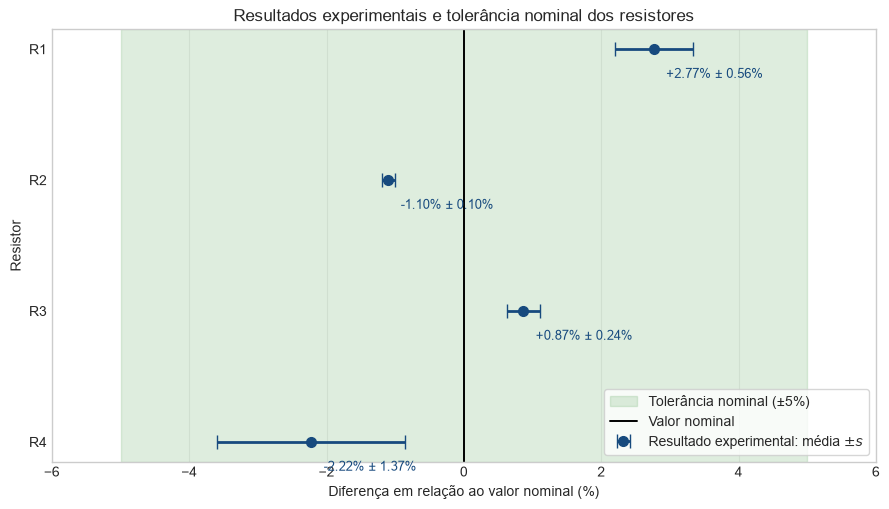

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.2))

y = np.arange(len(resistores))

ax.axvspan(-5, 5, color='#6BAF6B', alpha=0.22,
           label='Tolerância nominal (±5%)')
ax.axvline(0, color='black', linewidth=1.4,
           label='Valor nominal')

ax.errorbar(
    diferenca_percentual,
    y,
    xerr=desvio_percentual,
    fmt='o',
    color='#174A7E',
    ecolor='#174A7E',
    elinewidth=2,
    capsize=5,
    markersize=7,
    label=r'Resultado experimental: média $\pm s$',
)

for yi, diferenca, erro in zip(y, diferenca_percentual, desvio_percentual):
    ax.text(
        diferenca + 0.18, yi + 0.22,
        f'{diferenca:+.2f}% ± {erro:.2f}%',
        fontsize=9, color='#174A7E'
    )

ax.set_yticks(y, resistores)
ax.invert_yaxis()
ax.set_xlim(-6, 6)
ax.set_xlabel('Diferença em relação ao valor nominal (%)')
ax.set_ylabel('Resistor')
ax.set_title('Resultados experimentais e tolerância nominal dos resistores')
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='x', alpha=0.35)
ax.grid(axis='y', visible=False)
fig.tight_layout()

fig.savefig(
    'grafico_resistencias_tolerancia_percentual.png',
    dpi=300, bbox_inches='tight'
)

plt.show()

### Interpretação

Os quatro intervalos experimentais $\bar R\pm s$ estão totalmente contidos nas respectivas faixas de tolerância de $\pm5\%$. Entretanto, nenhum dos intervalos $\bar R\pm s$ contém exatamente o valor nominal. Isso não constitui contradição: o valor nominal é um ponto central de referência, enquanto a especificação do fabricante admite qualquer valor dentro da faixa de tolerância.

## 4. Visualização em ohms, separada por resistor

Como os valores nominais variam de $47\,\Omega$ a $330\,\Omega$, cada resistor recebe seu próprio eixo horizontal. A faixa verde é a tolerância nominal; a linha tracejada é o valor nominal; e o ponto com barra horizontal é $\bar R\pm s$.

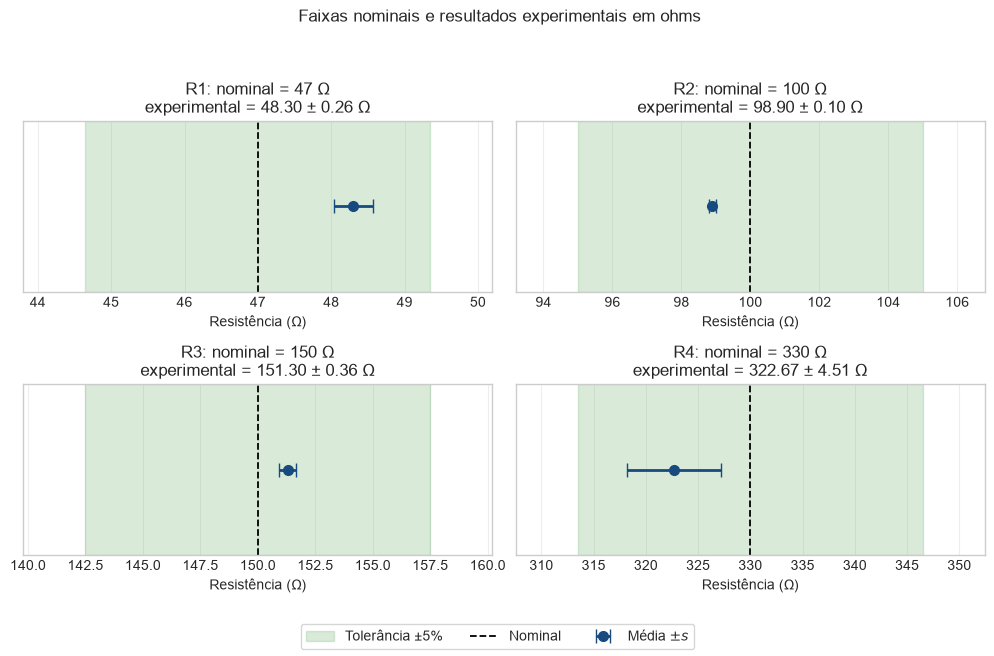

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
axes = axes.ravel()

for i, ax in enumerate(axes):
    ax.axvspan(
        tolerancia_inferior[i], tolerancia_superior[i],
        color='#6BAF6B', alpha=0.25, label='Tolerância ±5%'
    )
    ax.axvline(
        nominais[i], color='black', linestyle='--',
        linewidth=1.3, label='Nominal'
    )
    ax.errorbar(
        medias[i], 0, xerr=desvios[i], fmt='o',
        color='#174A7E', ecolor='#174A7E',
        elinewidth=2, capsize=5, markersize=7,
        label=r'Média $\pm s$'
    )

    margem = (tolerancia_superior[i] - tolerancia_inferior[i]) * 0.18
    ax.set_xlim(tolerancia_inferior[i] - margem,
                tolerancia_superior[i] + margem)
    ax.set_ylim(-0.7, 0.7)
    ax.set_yticks([])
    ax.set_xlabel('Resistência (Ω)')
    ax.set_title(
        f'{resistores[i]}: nominal = {nominais[i]:g} Ω\n'
        f'experimental = {medias[i]:.2f} ± {desvios[i]:.2f} Ω'
    )
    ax.grid(axis='x', alpha=0.35)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=True)
fig.suptitle('Faixas nominais e resultados experimentais em ohms', y=0.99)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))

fig.savefig(
    'grafico_resistencias_tolerancia_ohms.png',
    dpi=300, bbox_inches='tight'
)

plt.show()

## 5. Sugestão de legenda para o relatório

**Figura —** Comparação entre os resultados experimentais das resistências e a tolerância nominal de $\pm5\%$. A linha vertical em $0\%$ representa o valor nominal, a faixa verde indica a tolerância especificada e os pontos com barras horizontais representam a diferença percentual da média acompanhada de $\pm s$.